In [2]:
# ==========================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import os
import zipfile
from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ==========================================
# STEP 2: PROJECT DIRECTORY SETUP
# ==========================================

CURRENT_DIR = Path.cwd()

print("Current Working Directory:", CURRENT_DIR)

# Locate the main project folder
if (CURRENT_DIR / "dataset").exists():
    PROJECT_DIR = CURRENT_DIR

elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_DIR = CURRENT_DIR.parent

else:
    raise FileNotFoundError("Project folder not found!")

# Define dataset folders
RAW_DIR = PROJECT_DIR / "dataset" / "raw"
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

# Create folders if they don't exist
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("\nProject Directory:", PROJECT_DIR)
print("Raw Dataset Folder:", RAW_DIR)
print("Processed Dataset Folder:", PROCESSED_DIR)

Current Working Directory: c:\Users\Swapnil\OneDrive\Desktop\ML project\notebooks

Project Directory: c:\Users\Swapnil\OneDrive\Desktop\ML project
Raw Dataset Folder: c:\Users\Swapnil\OneDrive\Desktop\ML project\dataset\raw
Processed Dataset Folder: c:\Users\Swapnil\OneDrive\Desktop\ML project\dataset\processed


In [4]:
# ==========================================
# STEP 3: LOCATE ZIP DATASET
# ==========================================

zip_files = list(PROJECT_DIR.glob("*.zip"))

if len(zip_files) == 0:
    raise FileNotFoundError(
        "ZIP file not found in the main project folder!"
    )

zip_path = zip_files[0]

print("ZIP Dataset Found Successfully!")
print("File Name:", zip_path.name)
print("File Location:", zip_path)

ZIP Dataset Found Successfully!
File Name: MachineLearningCSV.zip
File Location: c:\Users\Swapnil\OneDrive\Desktop\ML project\MachineLearningCSV.zip


In [5]:
# ==========================================
# STEP 4: INSPECT ZIP DATASET
# ==========================================

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    csv_files = [
        file for file in zip_ref.namelist()
        if file.lower().endswith('.csv')
        and not file.startswith('__MACOSX/')
    ]

    print("Total CSV Files Found:", len(csv_files))

    print("\nDataset File Names:\n")

    for i, file in enumerate(csv_files, start=1):
        print(f"{i}. {Path(file).name}")

Total CSV Files Found: 8

Dataset File Names:

1. Wednesday-workingHours.pcap_ISCX.csv
2. Tuesday-WorkingHours.pcap_ISCX.csv
3. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
4. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
5. Monday-WorkingHours.pcap_ISCX.csv
6. Friday-WorkingHours-Morning.pcap_ISCX.csv
7. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
8. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


In [6]:
# ==========================================
# STEP 5: EXTRACT DATASETS
# ==========================================

with zipfile.ZipFile(zip_path, 'r') as zip_ref:

    for file in csv_files:

        filename = Path(file).name

        destination = RAW_DIR / filename

        with zip_ref.open(file) as source:
            with open(destination, 'wb') as target:
                target.write(source.read())

        print("Extracted:", filename)

print("\nAll datasets extracted successfully!")

Extracted: Wednesday-workingHours.pcap_ISCX.csv
Extracted: Tuesday-WorkingHours.pcap_ISCX.csv
Extracted: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Extracted: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Extracted: Monday-WorkingHours.pcap_ISCX.csv
Extracted: Friday-WorkingHours-Morning.pcap_ISCX.csv
Extracted: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Extracted: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

All datasets extracted successfully!


In [7]:
# ==========================================
# STEP 6: VERIFY DATASETS
# ==========================================

extracted_files = sorted(RAW_DIR.glob("*.csv"))

print("Total Extracted CSV Files:", len(extracted_files))

print("\nDataset Details:\n")

for i, file in enumerate(extracted_files, start=1):

    file_size = file.stat().st_size / (1024 * 1024)

    print(f"{i}. {file.name}")
    print(f"   File Size: {file_size:.2f} MB")

print("\nDataset Verification Completed!")

Total Extracted CSV Files: 8

Dataset Details:

1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
   File Size: 73.55 MB
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
   File Size: 73.34 MB
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
   File Size: 55.62 MB
4. Monday-WorkingHours.pcap_ISCX.csv
   File Size: 168.73 MB
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
   File Size: 79.25 MB
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
   File Size: 49.61 MB
7. Tuesday-WorkingHours.pcap_ISCX.csv
   File Size: 128.82 MB
8. Wednesday-workingHours.pcap_ISCX.csv
   File Size: 214.74 MB

Dataset Verification Completed!


In [8]:
# STEP 7: DATASET OVERVIEW

import pandas as pd
from pathlib import Path

csv_files = sorted(RAW_DIR.glob("*.csv"))

dataset_summary = []

for file in csv_files:

    df = pd.read_csv(file, nrows=5)

    dataset_summary.append({
        "File Name": file.name,
        "Columns": len(df.columns),
        "File Size (MB)": round(
            file.stat().st_size / (1024 * 1024), 2
        ),
        "Label Column": any(
            col.strip().lower() == "label"
            for col in df.columns
        )
    })

summary_df = pd.DataFrame(dataset_summary)

display(summary_df)

print("Total CSV files:", len(csv_files))

,File Name,Columns,File Size (MB),Label Column
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,79,73.55,True
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,79,73.34,True
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,79,55.62,True
3,Monday-WorkingHours.pcap_ISCX.csv,79,168.73,True
4,Thursday-WorkingHours-Afternoon-Infilteration....,79,79.25,True
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,79,49.61,True
6,Tuesday-WorkingHours.pcap_ISCX.csv,79,128.82,True
7,Wednesday-workingHours.pcap_ISCX.csv,79,214.74,True


Total CSV files: 8


In [9]:
# STEP 8: CHECK COLUMN CONSISTENCY

reference_columns = None

for file in csv_files:

    df = pd.read_csv(file, nrows=1)

    columns = set(
        col.strip() for col in df.columns
    )

    if reference_columns is None:
        reference_columns = columns

    print("\nFile:", file.name)
    print("Total columns:", len(columns))
    print("Missing columns:", len(reference_columns - columns))
    print("Additional columns:", len(columns - reference_columns))


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Monday-WorkingHours.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Tuesday-WorkingHours.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0

File: Wednesday-workingHours.pcap_ISCX.csv
Total columns: 79
Missing columns: 0
Additional columns: 0


In [10]:
# STEP 9: ATTACK LABEL DISTRIBUTION

label_summary = {}

for file in csv_files:

    for chunk in pd.read_csv(file, chunksize=100000):

        label_col = next(
            (col for col in chunk.columns
             if col.strip().lower() == "label"),
            None
        )

        if label_col is None:
            continue

        counts = chunk[label_col].astype(str).str.strip().value_counts()

        for label, count in counts.items():
            label_summary[label] = (
                label_summary.get(label, 0) + count
            )

label_df = pd.DataFrame(
    label_summary.items(),
    columns=["Attack Type", "Record Count"]
).sort_values("Record Count", ascending=False)

display(label_df)

print("Total records:", label_df["Record Count"].sum())

,Attack Type,Record Count
1,BENIGN,2273097
10,DoS Hulk,231073
2,PortScan,158930
0,DDoS,128027
13,DoS GoldenEye,10293
8,FTP-Patator,7938
9,SSH-Patator,5897
11,DoS slowloris,5796
12,DoS Slowhttptest,5499
3,Bot,1966


Total records: 2830743


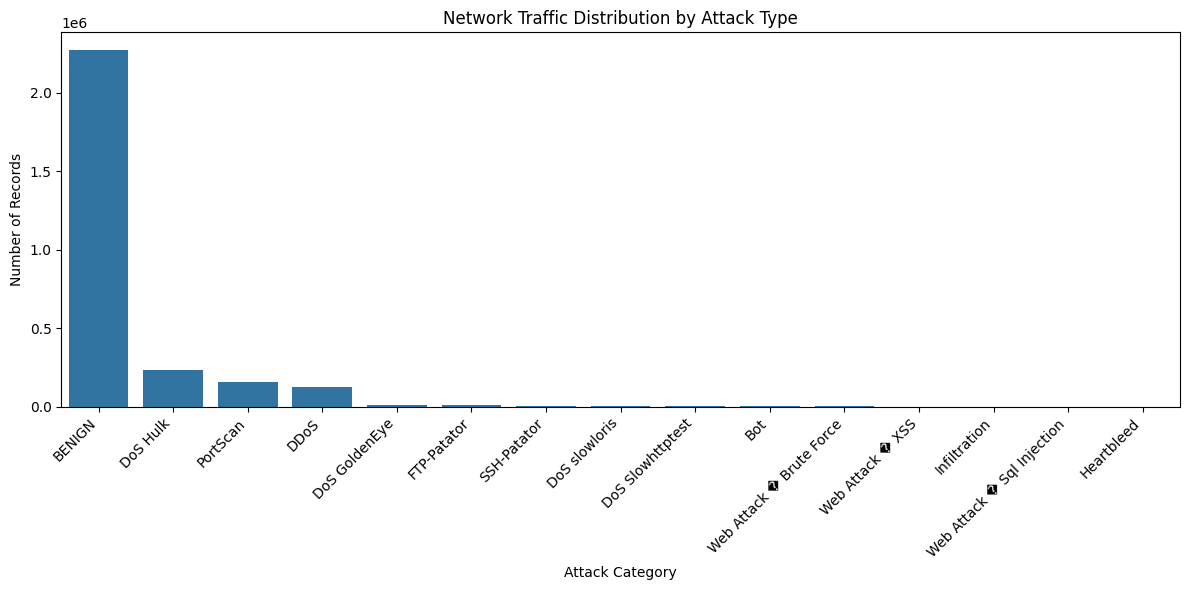

In [11]:
# STEP 10: ATTACK DISTRIBUTION VISUALISATION

plt.figure(figsize=(12, 6))

sns.barplot(
    data=label_df,
    x="Attack Type",
    y="Record Count"
)

plt.title("Network Traffic Distribution by Attack Type")
plt.xlabel("Attack Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
# Check data quality in each CSV file

for file in csv_files:
    df = pd.read_csv(file, nrows=10000)

    df.columns = df.columns.str.strip()

    print("\nFile:", file.name)
    print("Rows checked:", len(df))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Infinite values:", np.isinf(
        df.select_dtypes(include=np.number)
    ).sum().sum())


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows checked: 10000
Missing values: 1
Duplicate rows: 73
Infinite values: 13

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows checked: 10000
Missing values: 0
Duplicate rows: 137
Infinite values: 4

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows checked: 10000
Missing values: 0
Duplicate rows: 147
Infinite values: 12

File: Monday-WorkingHours.pcap_ISCX.csv
Rows checked: 10000
Missing values: 1
Duplicate rows: 127
Infinite values: 35

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows checked: 10000
Missing values: 0
Duplicate rows: 101
Infinite values: 8

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows checked: 10000
Missing values: 2
Duplicate rows: 134
Infinite values: 26

File: Tuesday-WorkingHours.pcap_ISCX.csv
Rows checked: 10000
Missing values: 10
Duplicate rows: 189
Infinite values: 18

File: Wednesday-workingHours.pcap_ISCX.csv
Rows checked: 10000
Missing values: